# Telugu Tokenizer Report For Phase-1

This notebook contains code and reports all the required statistics that are needed for submission in phase-1. I will also annotate parts and clarify the choices I have taken while implementing the project

Minimal AI help is taken to make this report

In [6]:
import json
from collections import Counter, defaultdict
from pathlib import Path


import sentencepiece as spm # used sentencepiece to train the Tokenizer
import matplotlib.pyplot as plt

## Corpus Examination

I sourced the corpus for Telugu from two sources. 
 - Wikimedia (wikipedia, wikisource, wiktionary, wikibooks)
 - Sangraha (verified tel i.e. not machine translated/synthetic)


Wikimedia is a rich source of human generated language and not to mention wikisource contains several thousand manuscripts/books that are out of copyright, thus forming a incredibly rich and diverse corpus. The dumps are also readily available, saving me many hours of internet scrapping.

In [12]:
INPUT_FILE = "data.nosync/telugu_combined_corpus_clean.jsonl"

75% of the characters are from Sangraha and the rest 25% is from wikimedia. This satisfies the criteria of 80:20 ratio given in project outline. Refer to `token_count_by_source_Telugu.json` for detailed stats

## Example Tokenization

In [9]:
MODEL_FILE = "models/telugu_sentencepiece_bpe_8k/telugu_bpe_8k.model"

# change 8k to 24k if you want to use the 24k model instead of the 8k model

In [46]:
sp = spm.SentencePieceProcessor(model_file=MODEL_FILE)

In [45]:
EXAMPLES = [
    "తెలుగు భారతదేశంలో మాట్లాడే ప్రధాన భాషలలో ఒకటి.",
    "కృత్రిమ మేధస్సు మరియు యంత్ర అభ్యాసం వేగంగా అభివృద్ధి చెందుతున్నాయి.",
    "నేను ఈ రోజు పుస్తకం చదువుతున్నాను.",
    "భారతదేశం ప్రపంచంలో అత్యధిక జనాభా కలిగిన దేశాలలో ఒకటి.",
    "ప్రకృతి మన జీవితంలో చాలా ముఖ్యమైన పాత్ర పోషిస్తుంది."
]

In [47]:
for text in EXAMPLES:
    pieces = sp.encode(text, out_type=str)
    ids = sp.encode(text, out_type=int)

    print(f"Original text: {text}")
    print(f"Tokenized pieces: {pieces}")
    print(f"Token IDs: {ids}")

Original text: తెలుగు భారతదేశంలో మాట్లాడే ప్రధాన భాషలలో ఒకటి.
Tokenized pieces: ['▁తెలుగు', '▁భారతదేశంలో', '▁మాట్లాడే', '▁ప్రధాన', '▁భాష', 'లలో', '▁ఒకటి', '.']
Token IDs: [707, 5940, 7541, 775, 1762, 357, 1415, 7870]
Original text: కృత్రిమ మేధస్సు మరియు యంత్ర అభ్యాసం వేగంగా అభివృద్ధి చెందుతున్నాయి.
Tokenized pieces: ['▁కృత్రిమ', '▁మే', 'ధ', 'స్సు', '▁మరియు', '▁యంత్ర', '▁అభ', '్యా', 'సం', '▁వేగంగా', '▁అభివృద్ధి', '▁చెందు', 'తున్నాయి', '.']
Token IDs: [7722, 339, 7881, 928, 250, 7807, 2565, 92, 226, 4778, 1225, 5056, 1114, 7870]
Original text: నేను ఈ రోజు పుస్తకం చదువుతున్నాను.
Tokenized pieces: ['▁నేను', '▁ఈ', '▁రోజు', '▁పుస్తకం', '▁చదువు', 'తున్నాను', '.']
Token IDs: [779, 79, 461, 7306, 2370, 6839, 7870]
Original text: భారతదేశం ప్రపంచంలో అత్యధిక జనాభా కలిగిన దేశాలలో ఒకటి.
Tokenized pieces: ['▁భారతదేశం', '▁ప్రపంచంలో', '▁అత్యధిక', '▁జనాభా', '▁కలిగిన', '▁దేశ', 'ాలలో', '▁ఒకటి', '.']
Token IDs: [6984, 5706, 4048, 2382, 3004, 451, 953, 1415, 7870]
Original text: ప్రకృతి మన జీవితంలో చాలా ముఖ

## Tokenizer Analysis

I trained two BPE model tokenizers with different vocabulary sizes (8k, 24k). I have ensured that in reference to both the tokenizer the 500M token mark is reached.

You can change the model defined in the below cell to get stats of the tokenizer of your choice.

In [17]:
from utils.tokenizer_evaluation import TokenizerEvaluator

evaluator = TokenizerEvaluator(input_file=INPUT_FILE, model_file=MODEL_FILE)
evaluator.process_corpus()


PROCESSING CORPUS
Processed: 10,000 | Tokens: 8,928,593
Processed: 20,000 | Tokens: 18,372,309
Processed: 30,000 | Tokens: 29,198,235
Processed: 40,000 | Tokens: 40,122,588
Processed: 50,000 | Tokens: 49,707,910
Processed: 60,000 | Tokens: 59,120,978
Processed: 70,000 | Tokens: 73,571,368
Processed: 80,000 | Tokens: 81,663,093
Processed: 90,000 | Tokens: 87,202,182
Processed: 100,000 | Tokens: 92,700,340
Processed: 110,000 | Tokens: 98,245,633
Processed: 120,000 | Tokens: 103,677,959
Processed: 130,000 | Tokens: 109,173,657
Processed: 140,000 | Tokens: 114,621,432
Processed: 150,000 | Tokens: 120,222,789
Processed: 160,000 | Tokens: 125,620,157
Processed: 170,000 | Tokens: 131,086,561
Processed: 180,000 | Tokens: 136,536,986
Processed: 190,000 | Tokens: 141,904,931
Processed: 200,000 | Tokens: 147,246,571
Processed: 210,000 | Tokens: 152,720,822
Processed: 220,000 | Tokens: 158,206,561
Processed: 230,000 | Tokens: 163,712,642
Processed: 240,000 | Tokens: 169,259,466
Processed: 250,000 

#### Total Token Count

In [18]:
token_count = evaluator.get_total_token_count()
print(f"Total tokens in the corpus: {token_count}")

Total tokens in the corpus: {'documents': 1204196, 'characters': 2315230491, 'tokens': 641752789}


#### Token percentage by source

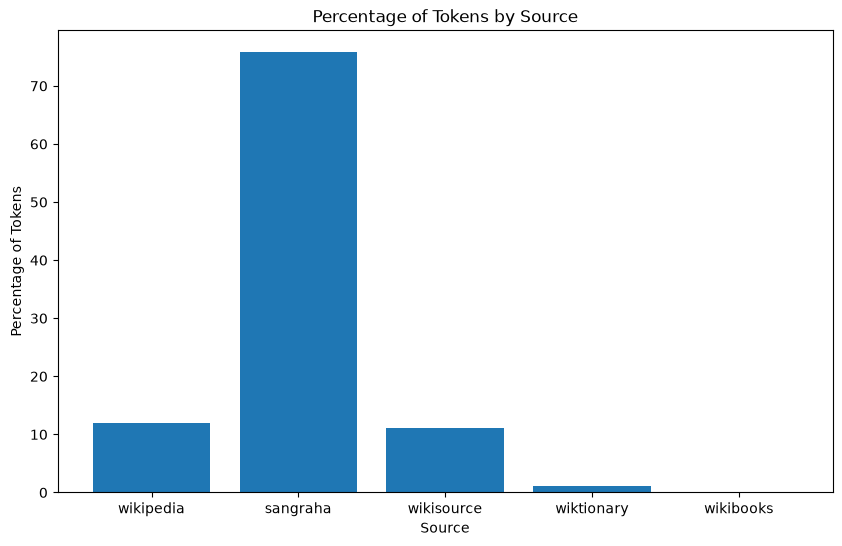

In [22]:
results = evaluator.get_token_percentage_by_source()

sources = list(results.keys())
percentages = {source: results[source]["token_percentage"] for source in sources}

plt.figure(figsize=(10, 6))
plt.bar(sources, percentages.values())
plt.xlabel("Source")
plt.ylabel("Percentage of Tokens")
plt.title("Percentage of Tokens by Source")
plt.show()

#### unk statistics

In [25]:
unk_results = evaluator.get_unk_statistics()

print("Unknown Token Statistics:")
print(f"Total unknown tokens: {unk_results['total_unk_tokens']}")
print(f"documents with unknown tokens (percentage): {unk_results['documents_with_unk_percentage']:.2f}%")
print(f"unk token percentage: {unk_results['unk_token_percentage']:.2f}%")

Unknown Token Statistics:
Total unknown tokens: 678964
documents with unknown tokens (percentage): 12.80%
unk token percentage: 0.11%


#### Fertility

In [26]:
fertility_results = evaluator.get_fertility()
print("Fertility Statistics:")
print(f"Total number of words: {fertility_results['total_words']}")
print(f"Total number of tokens: {fertility_results['total_token_pieces']}")
print(f"Fertility (tokens per word): {fertility_results['fertility']:.2f}")

Fertility Statistics:
Total number of words: 291052982
Total number of tokens: 641752789
Fertility (tokens per word): 2.20


#### Vocabulary utilisation

In [27]:
vocabulary_results = evaluator.get_vocabulary_utilisation()

print("Vocabulary Utilisation Statistics:")
print(f"Total vocabulary size: {vocabulary_results['vocabulary_size']}")
print(f"Number of unique tokens used in the corpus: {vocabulary_results['used_tokens']}")
print(f"Percentage of vocabulary used: {vocabulary_results['vocabulary_utilisation_percentage']:.2f}%")

Vocabulary Utilisation Statistics:
Total vocabulary size: 8000
Number of unique tokens used in the corpus: 7997
Percentage of vocabulary used: 99.96%


#### Token distribution

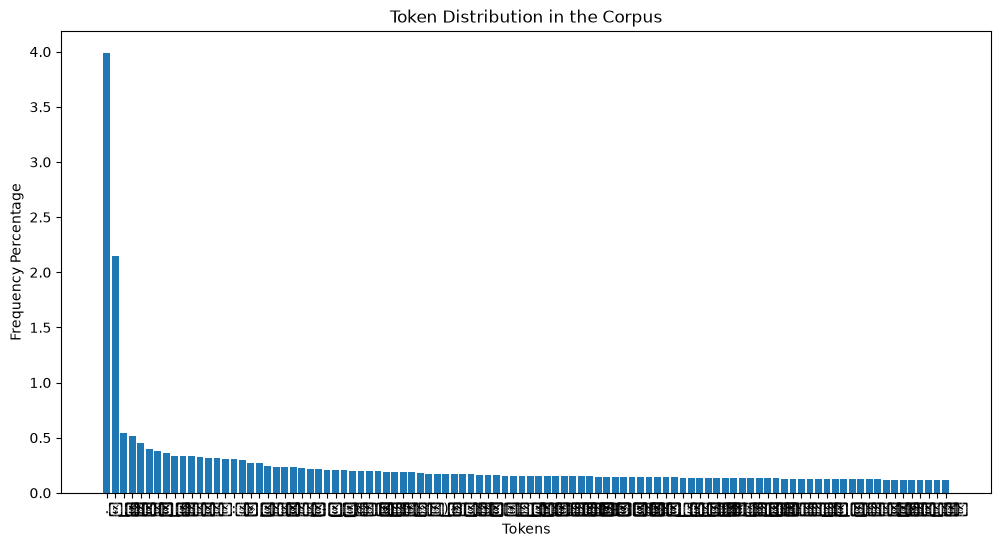

In [35]:
top_k = 100
token_distribution = evaluator.get_token_distribution(top_k=top_k)
Tokens = list(token_distribution[k]['token'] for k in range(top_k))
Frequency_percentage = list(token_distribution[k]['percentage'] for k in range(top_k))

plt.figure(figsize=(12, 6))
plt.bar(Tokens, Frequency_percentage)
plt.xlabel("Tokens")
plt.ylabel("Frequency Percentage")
plt.title("Token Distribution in the Corpus")
plt.show()

#### Rare Tokens

In [42]:
rare_tokens = evaluator.get_rare_tokens(max_frequency=160)['rare_tokens']

for i in range(len(rare_tokens)):
    token_info = rare_tokens[i]
    print(f"Token: {token_info['token']}, Frequency: {token_info['frequency']}")


Token: ▁Autom, Frequency: 46
Token: NOT, Frequency: 54
Token: ీవుడ్, Frequency: 75
Token: ▁తెరక, Frequency: 79
Token: లంగాణ, Frequency: 106
Token: obiles, Frequency: 112
Token: estyle, Frequency: 118


Rare tokens are mostly in english, which is what I expected

#### Token Lengths

In [43]:
token_length_stats = evaluator.get_average_token_length()

print("Token length statistics:")
print(f"Average token length: {token_length_stats['average_token_length']:.2f}")
print(f"Minimum token length: {token_length_stats['minimum_token_length']}")
print(f"Maximum token length: {token_length_stats['maximum_token_length']}")

Token length statistics:
Average token length: 4.47
Minimum token length: 0
Maximum token length: 15
